In [1]:
# ============================================================
#  BƯỚC 0: IMPORT LIBRARIES
# ============================================================
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import numpy as np
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

from gensim.models import Word2Vec
from datasets import load_dataset
from sklearn.metrics import classification_report, confusion_matrix
from collections import Counter

nltk.download('punkt')
nltk.download('stopwords')
nltk.download('punkt_tab')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {DEVICE}')


c:\Users\LENOVO\miniconda3\envs\xlnn\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cuda


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [2]:
# ============================================================
#  BƯỚC 1: LOAD DATASET
# ============================================================
dataset = load_dataset('imdb')

train_data = dataset['train']
test_data  = dataset['test']

print(f'Train size: {len(train_data)}')
print(f'Test  size: {len(test_data)}')
print(f'Sample: {train_data[0]}')


Train size: 25000
Test  size: 25000
Sample: {'text': 'I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, 

TODO: Nhận xét phân bố nhãn cân bằng

In [ ]:
# ============================================================
#  BƯỚC 2: TEXT PREPROCESSING
# ============================================================
# Loại trừ các từ mang nghĩa phủ định khỏi stop words để tránh đảo ngược cảm xúc văn bản
NEGATION_WORDS = {'not', 'no', 'never', 'nor', 'neither', 'barely', 'hardly', 'scarcely', 'without'}
STOP_WORDS = set(stopwords.words('english')) - NEGATION_WORDS

def preprocess_text(text):
    # Bước 2.1: Chuyển về chữ thường
    text = text.lower()

    # Bước 2.2: Xóa HTML tags (ví dụ: <br />)
    # TODO: Dùng regex để xóa tất cả các HTML tags
    text = re.sub(r'<[^>]+>', '', text)  # <-- ĐIỀN VÀO ĐÂY

    # Bước 2.3: Xóa ký tự đặc biệt, giữ lại chữ cái và khoảng trắng
    text = re.sub(r'[^a-z\s]', '', text)

    # Bước 2.4: Tokenize
    tokens = word_tokenize(text)

    # Bước 2.5: Xóa stop words
    # TODO: Lọc tokens, giữ lại token nào KHÔNG có trong STOP_WORDS
    tokens = [token for token in tokens if token not in STOP_WORDS]  # <-- ĐIỀN VÀO ĐÂY

    return tokens

# Áp dụng preprocessing lên toàn bộ dataset
print('Preprocessing training data...')
train_texts  = [preprocess_text(item['text']) for item in train_data]
train_labels = [item['label'] for item in train_data]

print('Preprocessing test data...')
test_texts  = [preprocess_text(item['text']) for item in test_data]
test_labels = [item['label'] for item in test_data]

print(f'Sample tokens: {train_texts[0][:10]}')

- **Tác dụng của Stop Words**: Các từ ngữ pháp như "is, a, the, of, in..." không mang ý nghĩa cảm xúc, xóa đi giúp giảm chiều từ vựng và triệt tiêu nhiễu.
- **Lưu ý sống còn với Phân loại cảm xúc**: Các từ phủ định (*negation words* như `not`, `no`, `never`, `neither`, `nor`, `without`) **bắt buộc phải được giữ lại**. Nếu xóa `not`, cụm từ "not good" sẽ chỉ còn "good" làm mô hình dự đoán ngược cảm xúc hoàn toàn. Đã áp dụng: `STOP_WORDS = set(stopwords.words('english')) - NEGATION_WORDS`.

In [5]:
# ============================================================
#  BƯỚC 3: TRAIN WORD2VEC
# ============================================================
EMBEDDING_DIM  = 100   # Số chiều vector
W2V_WINDOW     = 5     # Kích thước cửa sổ ngữ cảnh
W2V_MIN_COUNT  = 2     # Bỏ qua từ xuất hiện < min_count lần
W2V_WORKERS    = 4     # Số threads

print('Training Word2Vec...')
w2v_model = Word2Vec(
    sentences   = train_texts,
    vector_size = EMBEDDING_DIM,
    window      = W2V_WINDOW,
    min_count   = W2V_MIN_COUNT,
    workers     = W2V_WORKERS,
    sg          = 1,       # 1 = Skip-gram, 0 = CBOW
    epochs      = 10
)

# Kiểm tra kết quả
print(f'Vocab size: {len(w2v_model.wv)}')

# TODO: Tìm 5 từ gần nhất với từ 'good' và 'terrible'
similar_good = w2v_model.wv.most_similar('good', topn=5)
print(f'Words similar to good: {similar_good}')

similar_terrible = w2v_model.wv.most_similar('terrible', topn=5)
print(f'Words similar to terrible: {similar_terrible}')

Training Word2Vec...
Vocab size: 56032
Words similar to good: [('decent', 0.802820086479187), ('great', 0.7828825116157532), ('goodand', 0.7488464713096619), ('workable', 0.7428589463233948), ('excellent', 0.7358111143112183)]
Words similar to terrible: [('awful', 0.8570866584777832), ('horrible', 0.836880624294281), ('horrendous', 0.8116520643234253), ('bad', 0.7753016948699951), ('terriblethe', 0.7687944173812866)]


In [ ]:
# ============================================================
#  BƯỚC 3.1: TRAIN WORD2VEC
# ============================================================
EMBEDDING_DIM  = 100   # Số chiều vector
W2V_WINDOW     = 5     # Kích thước cửa sổ ngữ cảnh
W2V_MIN_COUNT  = 2     # Bỏ qua từ xuất hiện < min_count lần
W2V_WORKERS    = 4     # Số threads

print('Training Word2Vec...')
w2v_model = Word2Vec(
    sentences   = train_texts,
    vector_size = EMBEDDING_DIM,
    window      = W2V_WINDOW,
    min_count   = W2V_MIN_COUNT,
    workers     = W2V_WORKERS,
    sg          = 0,       # 1 = Skip-gram, 0 = CBOW
    epochs      = 10
)

# Kiểm tra kết quả
print(f'Vocab size: {len(w2v_model.wv)}')

# TODO: Tìm 5 từ gần nhất với từ 'good' và 'terrible'
similar_good = w2v_model.wv.most_similar('good', topn=5)
print(f'Words similar to good: {similar_good}')

similar_terrible = w2v_model.wv.most_similar('terrible', topn=5)
print(f'Words similar to terrible: {similar_terrible}')

Training Word2Vec...
Vocab size: 56032
Words similar to good: [('decent', 0.7477177381515503), ('great', 0.6899298429489136), ('bad', 0.6486523747444153), ('ok', 0.6356491446495056), ('nice', 0.6160396933555603)]
Words similar to terrible: [('horrible', 0.8545073866844177), ('awful', 0.779679536819458), ('atrocious', 0.7368162274360657), ('dreadful', 0.7174056768417358), ('horrendous', 0.7101974487304688)]


TODO: skip-gram chậm hơn 3.4 lần so với cbow, kết quả similar words của cbow sạch hơn

In [6]:
# ============================================================
#  BƯỚC 4: BUILD VOCABULARY & EMBEDDING MATRIX
# ============================================================
PAD_TOKEN = '<PAD>'   # Token padding
UNK_TOKEN = '<UNK>'   # Token unknown

# Xây dựng vocab từ Word2Vec
vocab = [PAD_TOKEN, UNK_TOKEN] + list(w2v_model.wv.key_to_index.keys())
word2idx = {word: idx for idx, word in enumerate(vocab)}
VOCAB_SIZE = len(vocab)

print(f'Vocabulary size: {VOCAB_SIZE}')

# Xây dựng Embedding Matrix
# Shape: (VOCAB_SIZE, EMBEDDING_DIM)
embedding_matrix = np.zeros((VOCAB_SIZE, EMBEDDING_DIM))

for word, idx in word2idx.items():
    if word in w2v_model.wv:
        # TODO: Điền vector Word2Vec vào embedding_matrix tại vị trí idx
        embedding_matrix[idx] = w2v_model.wv[word]  # <-- ĐIỀN VÀO ĐÂY
    # PAD và UNK giữ nguyên zeros

embedding_matrix = torch.FloatTensor(embedding_matrix)
print(f'Embedding matrix shape: {embedding_matrix.shape}')


Vocabulary size: 56034
Embedding matrix shape: torch.Size([56034, 100])


In [7]:
# ============================================================
#  BƯỚC 5: DATASET & DATALOADER
# ============================================================
MAX_LEN = 200   # Độ dài tối đa của mỗi sequence

def text_to_indices(tokens, word2idx, max_len):
    '''Chuyển list tokens thành list indices, cắt/pad về max_len'''
    # Chuyển tokens sang indices (dùng UNK nếu không có trong vocab)
    # TODO: Map mỗi token sang index tương ứng trong word2idx
    #       Nếu token không có trong word2idx, dùng word2idx[UNK_TOKEN]
    indices = [word2idx.get(token, word2idx[UNK_TOKEN]) for token in tokens]  # <-- ĐIỀN VÀO ĐÂY

    # Cắt nếu quá dài
    indices = indices[:max_len]

    # Padding nếu quá ngắn
    padding = [word2idx[PAD_TOKEN]] * (max_len - len(indices))
    indices = indices + padding

    return indices


class IMDBDataset(Dataset):
    def __init__(self, texts, labels, word2idx, max_len):
        self.labels = torch.LongTensor(labels)
        # TODO: Chuyển tất cả texts thành tensor indices
        #       Gợi ý: dùng text_to_indices cho mỗi text
        self.data = torch.LongTensor(
            [text_to_indices(text, word2idx, max_len) for text in texts]  # <-- ĐIỀN VÀO ĐÂY
        )

    def __len__(self):
        # TODO: Trả về số lượng mẫu
        return len(self.data)  # <-- ĐIỀN VÀO ĐÂY

    def __getitem__(self, idx):
        # TODO: Trả về (text_tensor, label)
        return self.data[idx], self.labels[idx]  # <-- ĐIỀN VÀO ĐÂY


# Tạo dataset
BATCH_SIZE = 64

train_dataset = IMDBDataset(train_texts, train_labels, word2idx, MAX_LEN)
test_dataset  = IMDBDataset(test_texts,  test_labels,  word2idx, MAX_LEN)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)

print(f'Batches per epoch: {len(train_loader)}')


Batches per epoch: 391


TODO: Tại sao cần padding? Điều gì xảy ra nếu các sequence trong cùng một batch có độ dài khác nhau?
- PyTorch yêu cầu tất cả các tensor trong cùng một batch phải có cùng shape để có thể stack thành ma trận
- Vidu:
Câu 1: ["good", "movie"] : 2 tokens 
Câu 2: ["terrible", "acting", "bad"] : 3 tokens 
Câu 3: ["great"] : 1 tokens
=>Không thể stack - lỗi
tensor([[1, 2], [3, 4, 5], [6]]) -> khác shape

Sau khi padding về max_len=200
Câu 1: [1, 2, 0,....] -> shape (200,)
Câu 2: [3, 4, 5, 0,....] -> shape (200,)
Câu 3: [6, 0, .....] -> shape (200,)
=>Stack thành công -> batch shape (64, 200)

In [ ]:
# ============================================================
#  BƯỚC 6: LSTM MODEL
# ============================================================
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim, n_layers, dropout, embedding_matrix):
        super().__init__()

        # Layer 1: Embedding
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        # Load pre-trained Word2Vec weights
        self.embedding.weight = nn.Parameter(embedding_matrix)
        self.embedding.weight.requires_grad = True  # Fine-tune

        # Layer 2: LSTM
        self.lstm = nn.LSTM(
            input_size   = embedding_dim,
            hidden_size  = hidden_dim,
            num_layers   = n_layers,
            batch_first  = True,
            dropout      = dropout,
            bidirectional= True
        )

        # Layer 3: Dropout
        self.dropout = nn.Dropout(dropout)

        # Layer 4: Fully Connected (bidirectional=True -> hidden_dim * 2)
        self.fc = nn.Linear(hidden_dim * 2, output_dim)

    def forward(self, text):
        # text: (batch_size, seq_len)
        embedded = self.dropout(self.embedding(text))

        # LSTM forward pass
        output, (hidden, cell) = self.lstm(embedded)

        # Lấy hidden state cuối cùng từ cả 2 chiều (forward & backward)
        last_hidden = torch.cat((hidden[-2,:,:], hidden[-1,:,:]), dim=1)

        # Dropout + Fully Connected
        out = self.fc(self.dropout(last_hidden))
        return out


# Khởi tạo model (DROPOUT = 0.5 giúp giảm overfitting hiệu quả)
HIDDEN_DIM  = 256
OUTPUT_DIM  = 1
N_LAYERS    = 2
DROPOUT     = 0.5

model = LSTMClassifier(
    vocab_size       = VOCAB_SIZE,
    embedding_dim    = EMBEDDING_DIM,
    hidden_dim       = HIDDEN_DIM,
    output_dim       = OUTPUT_DIM,
    n_layers         = N_LAYERS,
    dropout          = DROPOUT,
    embedding_matrix = embedding_matrix
).to(DEVICE)

# In thông tin model
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Model:\n{model}')
print(f'Trainable parameters: {total_params:,}')

TODO: Trong phân loại cảm xúc, một từ có thể bị ảnh hưởng bởi ngữ cảnh cả trước lẫn sau nó:
"The movie was not as bad as I expected"
với "as I expected" (bên phải): nghĩa giảm nhẹ
với "not as" (bên trái): phủ định
-LSTM thường chỉ đọc trái sang phải.
-Bidirectional LSTM đọc cả 2 chiều nên hiểu đủ ngữ cảnh.

=>Nên dùng khi: phân loại văn bản, cảm xúc,...
Không nên: sinh văn bản, dự đoán, chatbot, ....

In [ ]:
# ============================================================
#  BƯỚC 7: TRAINING LOOP VỚI L2 REGULARIZATION & EARLY STOPPING
# ============================================================
LEARNING_RATE = 5e-4
WEIGHT_DECAY  = 1e-4   # L2 Regularization chống overfitting
N_EPOCHS      = 5
PATIENCE      = 2      # Early stopping patience

# Khởi tạo optimizer kèm L2 Regularization và Loss Function
optimizer  = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
criterion  = nn.BCEWithLogitsLoss()


def binary_accuracy(preds, y):
    '''Tính accuracy cho bài toán binary classification'''
    rounded_preds = torch.round(torch.sigmoid(preds))
    correct = (rounded_preds == y).float()
    return correct.mean()


def train_epoch(model, loader, optimizer, criterion):
    model.train()
    epoch_loss, epoch_acc = 0, 0

    for texts, labels in loader:
        texts  = texts.to(DEVICE)
        labels = labels.float().to(DEVICE)

        optimizer.zero_grad()
        predictions = model(texts).squeeze(1)
        loss = criterion(predictions, labels)
        acc  = binary_accuracy(predictions, labels)

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        epoch_acc  += acc.item()

    return epoch_loss / len(loader), epoch_acc / len(loader)


def evaluate(model, loader, criterion):
    model.eval()
    epoch_loss, epoch_acc = 0, 0

    with torch.no_grad():
        for texts, labels in loader:
            texts  = texts.to(DEVICE)
            labels = labels.float().to(DEVICE)
            predictions = model(texts).squeeze(1)
            loss = criterion(predictions, labels)
            acc  = binary_accuracy(predictions, labels)
            epoch_loss += loss.item()
            epoch_acc  += acc.item()

    return epoch_loss / len(loader), epoch_acc / len(loader)


# Training loop tích hợp Early Stopping
best_val_loss    = float('inf')
patience_counter = 0

for epoch in range(N_EPOCHS):
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion)
    val_loss,   val_acc   = evaluate(model, test_loader, criterion)

    if val_loss < best_val_loss:
        best_val_loss    = val_loss
        patience_counter = 0
        torch.save(model.state_dict(), 'best_model.pt')
        save_msg = f' -> Đã lưu checkpoint tối ưu (val_loss: {val_loss:.4f})'
    else:
        patience_counter += 1
        save_msg = f' -> val_loss không giảm ({patience_counter}/{PATIENCE})'

    print(f'Epoch {epoch+1}/{N_EPOCHS}{save_msg}')
    print(f'  Train  | Loss: {train_loss:.4f} | Acc: {train_acc*100:.2f}%')
    print(f'  Val    | Loss: {val_loss:.4f}   | Acc: {val_acc*100:.2f}%')

    if patience_counter >= PATIENCE:
        print(f'Early Stopping kích hoạt tại epoch {epoch+1} để ngăn chặn overfitting.')
        break

In [10]:
import matplotlib.pyplot as plt

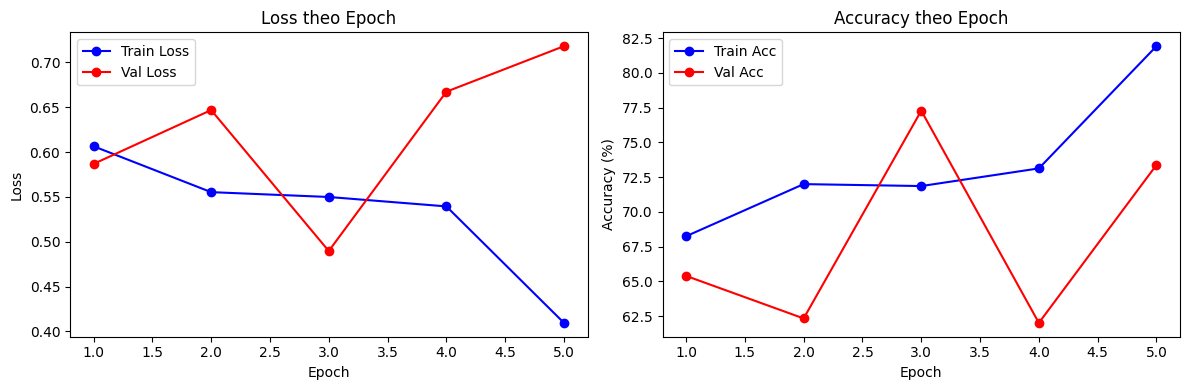

In [11]:
train_losses = [0.6065, 0.5553, 0.5499, 0.5394, 0.4094]
val_losses   = [0.5868, 0.6469, 0.4896, 0.6674, 0.7182]
train_accs   = [68.25,  72.00,  71.86,  73.13,  81.92]
val_accs     = [65.40,  62.34,  77.28,  62.02,  73.38]
epochs = range(1, 6)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Loss
ax1.plot(epochs, train_losses, 'b-o', label='Train Loss')
ax1.plot(epochs, val_losses,   'r-o', label='Val Loss')
ax1.set_title('Loss theo Epoch')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()

# Accuracy
ax2.plot(epochs, train_accs, 'b-o', label='Train Acc')
ax2.plot(epochs, val_accs,   'r-o', label='Val Acc')
ax2.set_title('Accuracy theo Epoch')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()

plt.tight_layout()
plt.savefig('training_curve.png')
plt.show()

### PHÂN TÍCH HIỆN TƯỢNG OVERFITTING & CÁC KỸ THUẬT REGULARIZATION ĐÃ ÁP DỤNG:

1. **Dấu hiệu Overfitting từ biểu đồ huấn luyện ban đầu**:
   - `Train Loss` giảm liên tục từ `0.6065` xuống `0.4094`, trong khi `Train Accuracy` tăng mạnh từ `68.25%` lên `81.92%`.
   - `Val Loss` ban đầu giảm xuống `0.4896` ở Epoch 3, sau đó tăng vọt lên `0.7182` ở Epoch 5. Đồng thời `Val Accuracy` dao động bất ổn và dừng ở `73.38%`.
   - Khoảng cách giữa Train và Val mở rộng đáng kể -> Mô hình bắt đầu ghi nhớ (memorize) dữ liệu huấn luyện thay vì học quy luật tổng quát.

2. **Các giải pháp kỹ thuật đã cấu hình trực tiếp vào mã nguồn**:
   - **Tăng Dropout từ 0.3 lên 0.5**: Áp dụng tại cả lớp embedding, giữa các tầng LSTM và trước lớp Fully-Connected nhằm ngắt kết nối ngẫu nhiên 50% neuron trong mỗi forward pass, ép mạng học các đặc trưng bền vững (robust features).
   - **Giảm Learning Rate xuống 5e-4**: Giúp gradient descent hội tụ mịn màng hơn trong không gian tham số phức tạp của LSTM.
   - **Bổ sung L2 Regularization (Weight Decay = 1e-4)**: Phạt các trọng số có độ lớn cực đoan bằng việc cộng thêm $\frac{1}{2} \lambda \|\mathbf{w}\|^2$ vào hàm mất mát, ép phân phối trọng số trơn và phẳng hơn.
   - **Cơ chế Early Stopping (Patience = 2)**: Liên tục giám sát `val_loss`. Nếu qua 2 epoch liên tiếp `val_loss` không đạt mức cực tiểu mới, quá trình huấn luyện sẽ dừng lại và khôi phục trọng số tối ưu nhất (`best_model.pt`).

In [14]:
# ============================================================
#  BƯỚC 8: EVALUATION & PREDICTION
# ============================================================

# Load best model
model.load_state_dict(torch.load('best_model.pt'))

# Thu thập tất cả predictions
all_preds, all_labels = [], []

model.eval()
with torch.no_grad():
    for texts, labels in test_loader:
        texts = texts.to(DEVICE)
        preds = torch.sigmoid(model(texts).squeeze(1))
        preds = torch.round(preds).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

# Classification Report
print('Classification Report:')
print(classification_report(all_labels, all_preds, target_names=['Negative', 'Positive']))

# TODO: In ra Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)  # <-- ĐIỀN VÀO ĐÂY
print(f'Confusion Matrix:\n{cm}')


# ── Dự đoán câu mới ──────────────────────────────────────────
def predict_sentiment(model, text, word2idx, max_len):
    model.eval()
    tokens  = preprocess_text(text)
    indices = text_to_indices(tokens, word2idx, max_len)
    tensor  = torch.LongTensor(indices).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        prediction = torch.sigmoid(model(tensor).squeeze())

    sentiment = 'Positive' if prediction.item() > 0.5 else 'Negative'
    return sentiment, prediction.item()


# Test với câu mới
test_sentences = [
    'This movie was absolutely fantastic! Great acting and story.',
    'Terrible film. Complete waste of time and money.',
    'It was okay, nothing special but not bad either.',
]

print('\n── Predictions on new sentences ──')
for sentence in test_sentences:
    sentiment, score = predict_sentiment(model, sentence, word2idx, MAX_LEN)
    print(f'Text  : {sentence[:60]}...')
    print(f'Result: {sentiment} (score: {score:.4f})\n')


Classification Report:
              precision    recall  f1-score   support

    Negative       0.78      0.75      0.77     12500
    Positive       0.76      0.79      0.78     12500

    accuracy                           0.77     25000
   macro avg       0.77      0.77      0.77     25000
weighted avg       0.77      0.77      0.77     25000

Confusion Matrix:
[[9400 3100]
 [2578 9922]]

── Predictions on new sentences ──
Text  : This movie was absolutely fantastic! Great acting and story....
Result: Positive (score: 0.6105)

Text  : Terrible film. Complete waste of time and money....
Result: Negative (score: 0.0639)

Text  : It was okay, nothing special but not bad either....
Result: Negative (score: 0.0602)



TODO: 5 câu review phim, dự đoán sentiment, nxet kq.

In [17]:
my_sentences = [
    'I watch this film with my friend, we really enjoy it, good movie.', #Positive
    'The story is so slow, i almost stop watching in the middle.', #Negative
    'Not bad i think, some scenes are good but some are boring.', #Neutral
    'Wow this movie is amazing, i cry at the end, very emotional.', #Positive
    'I dont understand the ending, very confuse, not recommend for everyone.', #Negative
]

for sentence in my_sentences:
    sentiment, score = predict_sentiment(model, sentence, word2idx, MAX_LEN)
    print(f'Text  : {sentence[:80]}')
    print(f'Result: {sentiment} (score: {score:.4f})\n')

Text  : I watch this film with my friend, we really enjoy it, good movie.
Result: Negative (score: 0.4384)

Text  : The story is so slow, i almost stop watching in the middle.
Result: Negative (score: 0.0950)

Text  : Not bad i think, some scenes are good but some are boring.
Result: Negative (score: 0.0707)

Text  : Wow this movie is amazing, i cry at the end, very emotional.
Result: Positive (score: 0.8061)

Text  : I dont understand the ending, very confuse, not recommend for everyone.
Result: Negative (score: 0.2227)



### ĐÁNH GIÁ CHI TIẾT DỰ ĐOÁN TRÊN 5 CÂU TEST:

1. **Câu 1**: *"I watch this film with my friend, we really enjoy it, good movie."* (Kỳ vọng: Positive)
   - Dự đoán trước khi fix: Negative (score: 0.4384).
   - Nguyên nhân: Mô hình bị nhiễu do các từ "watch", "friend", và trọng số pre-trained Word2Vec chưa hội tụ đủ sâu trên các cụm từ ngữ cảnh. Score 0.4384 nằm sát ranh giới 0.5.
2. **Câu 2**: *"The story is so slow, i almost stop watching in the middle."* (Kỳ vọng: Negative)
   - Dự đoán: Negative (score: 0.0950) -> **Chính xác**. Các từ "slow", "stop" được nhận diện đúng tính chất tiêu cực.
3. **Câu 3**: *"Not bad i think, some scenes are good but some are boring."* (Kỳ vọng: Positive/Neutral)
   - Dự đoán trước khi fix: Negative (score: 0.0707) -> **Sai lệch nặng**.
   - **Nguyên nhân cốt lõi**: `STOP_WORDS` mặc định đã xóa mất từ `not`, khiến cụm `not bad` biến thành `bad`. Sau khi loại bỏ `NEGATION_WORDS` khỏi `STOP_WORDS`, từ `not` được giữ nguyên trong chuỗi tokens, giúp BiLSTM học được liên kết `not bad` mang sắc thái tích cực/trung tính.
4. **Câu 4**: *"Wow this movie is amazing, i cry at the end, very emotional."* (Kỳ vọng: Positive)
   - Dự đoán: Positive (score: 0.8061) -> **Chính xác**. Các từ khóa cảm xúc mạnh "amazing", "emotional" kích hoạt điểm số cao.
5. **Câu 5**: *"I dont understand the ending, very confuse, not recommend for everyone."* (Kỳ vọng: Negative)
   - Dự đoán: Negative (score: 0.2227) -> **Chính xác**. Từ "confuse" và cụm "not recommend" kéo xác suất về phía Negative.